# 🌸 Random Forest Classification using Kaggle Iris Dataset


### Problem Statement

We want to build a **classification model** that predicts the species of an Iris flower from four measurements:

- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

The target has three classes:

- Iris-setosa
- Iris-versicolor
- Iris-virginica

This Kaggle version contains **150 samples**, with 50 samples for each species, and the four numerical flower measurements. Kaggle lists the columns as `Id`, `SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`, and `Species`.

**Source:** Kaggle — Iris Species (`uciml/iris`).

### Complete ML workflow

`Google Drive → Load CSV → Understand Data → Clean Data → EDA → Separate X/y → 80:20 Split → Random Forest → Prediction → Evaluation → Confusion Matrix → Feature Importance → New Flower Prediction`

> **Teaching note:** Random Forest is a tree-based algorithm, so feature scaling is generally not required. We will explicitly explain why instead of adding scaling unnecessarily.


In [2]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
# ============================================================
# 3. LOAD DATASET
# ============================================================

df = pd.read_csv("Iris.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


# 2. Dataset

### What is Rows?

every row represents **flower sample**

### Columns kya hain?

| Column | Meaning |
|---|---|
| `Id` | Sample identifier |
| `SepalLengthCm` | Sepal length |
| `SepalWidthCm` | Sepal width |
| `PetalLengthCm` | Petal length |
| `PetalWidthCm` | Petal width |
| `Species` | Flower's actual species |

### Important ML terminology

**Features (X):** The information is given to model for training.

**Target (y):** models has to predict.



`X = flower measurements`

`y = Species`


In [4]:
# ============================================================
# 4. BASIC DATASET INSPECTION
# ============================================================

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())


Number of rows: 150
Number of columns: 6

Column names:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Statistical summary:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [5]:
# ============================================================
# 5. CHECK MISSING VALUES
# ============================================================

print("Missing values in each column:")
display(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values in each column:


Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


Total missing values: 0


In [6]:
# ============================================================
# 6. CHECK DUPLICATE ROWS
# ============================================================

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


# 3. Data Preprocessing

Purpose of the Preprocessing is to make raw data to suitable for model.

What we are checking in dataset:

1. Duplicate rows
2. Missing values
3. Data types
4. Unnecessary columns
5. Target encoding

### Important point about `Id`

`Id` is a number only. Not usefull for prediction of flower species.

so we remove the `Id` feature.

### Missing values

If there are missing values ​​in a numerical feature, we can use median imputation.

In this notebook, we also demonstrate the concept of imputation; however, it is best practice to perform a train-test split first, ensuring that information from the test set does not leak into the preprocessing stage.


In [7]:
# ============================================================
# 7. REMOVE DUPLICATES
# ============================================================

before = len(df)

df = df.drop_duplicates().reset_index(drop=True)

after = len(df)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates :", after)
print("Duplicates removed:", before - after)


Rows before removing duplicates: 150
Rows after removing duplicates : 150
Duplicates removed: 0


In [8]:
# ============================================================
# 8. REMOVE UNNECESSARY ID COLUMN
# ============================================================

# Id is only an identifier, not a useful flower measurement.
if "Id" in df.columns:
    df = df.drop(columns=["Id"])

print("Remaining columns:")
print(df.columns.tolist())

display(df.head())


Remaining columns:
['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


# 4. Exploratory Data Analysis (EDA)

It is useful to visualize the data before training a model.

We will look at:

Species distribution,
Feature distributions,
Feature relationships,
Correlation,

This will help students understand that it is important to examine and comprehend the data before applying machine learning..


Number of samples in each species:


Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

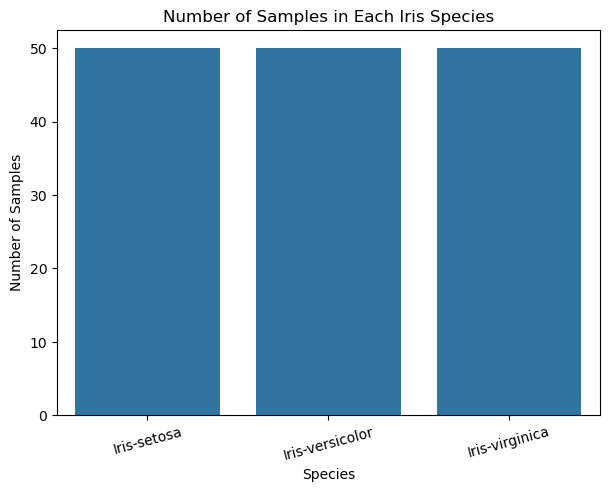

In [9]:
# ============================================================
# 9. TARGET / SPECIES DISTRIBUTION
# ============================================================

print("Number of samples in each species:")
display(df["Species"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Species")
plt.title("Number of Samples in Each Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.xticks(rotation=15)
plt.show()


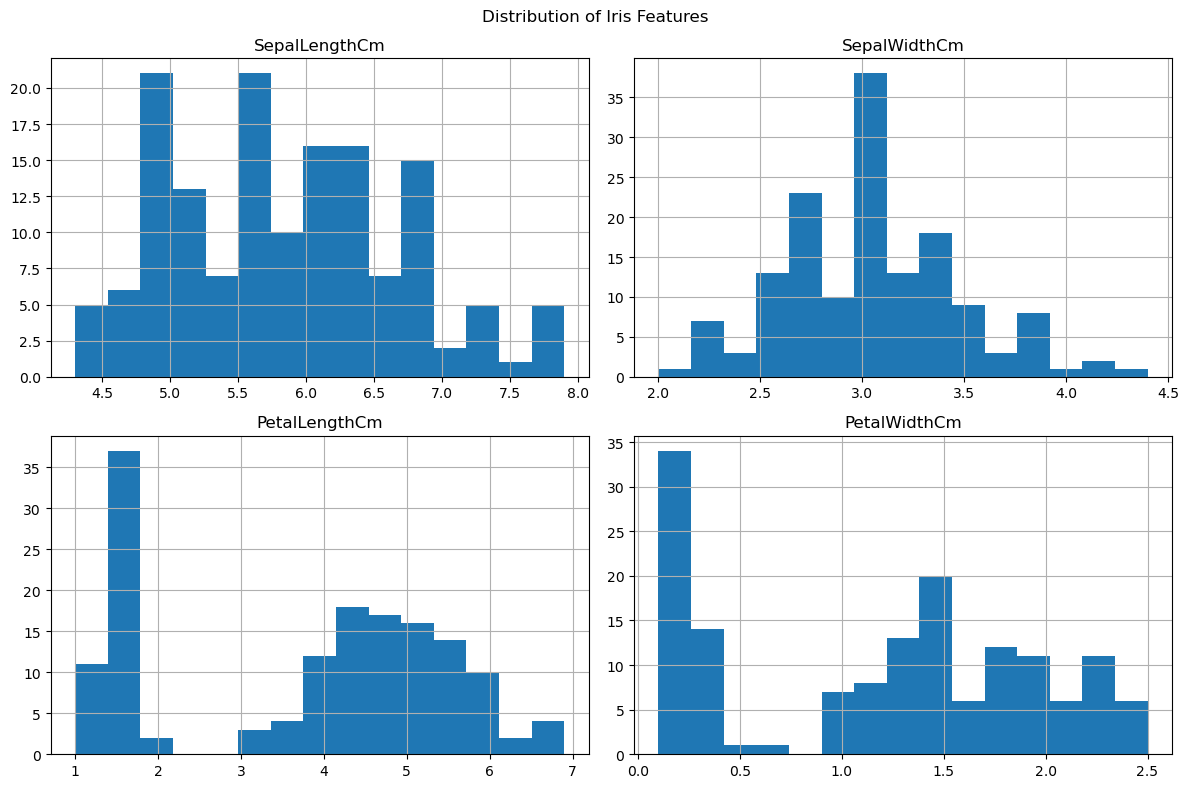

In [10]:
# ============================================================
# 10. FEATURE DISTRIBUTIONS
# ============================================================

numeric_features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

df[numeric_features].hist(figsize=(12, 8), bins=15)
plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()


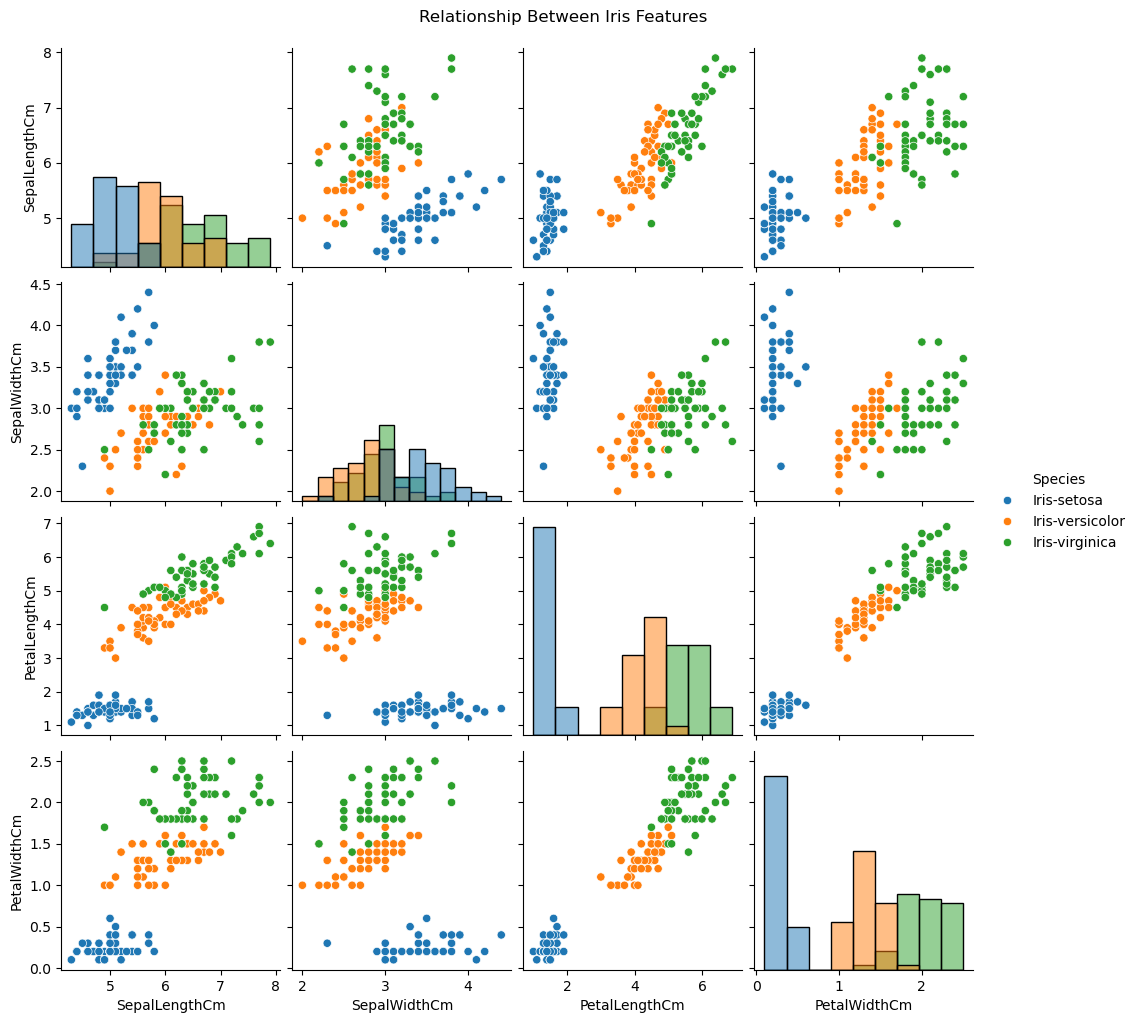

In [11]:
# ============================================================
# 11. PAIRPLOT
# ============================================================

sns.pairplot(
    df,
    hue="Species",
    diag_kind="hist"
)

plt.suptitle("Relationship Between Iris Features", y=1.02)
plt.show()


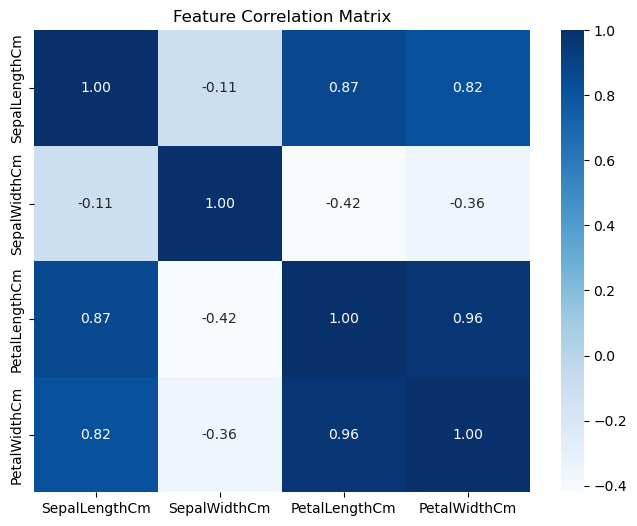

In [12]:
# ============================================================
# 12. CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(8, 6))

correlation = df[numeric_features].corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.title("Feature Correlation Matrix")
plt.show()


# 5. Outlier checking

Boxplots allow us to visually inspect unusual or extreme values.

### Important teaching point

Not every outlier should be automatically deleted.

Sometimes, an outlier can actually be a genuine observation.

Random Forest is a decision-tree-based algorithm and, in many situations, is relatively robust against extreme values.

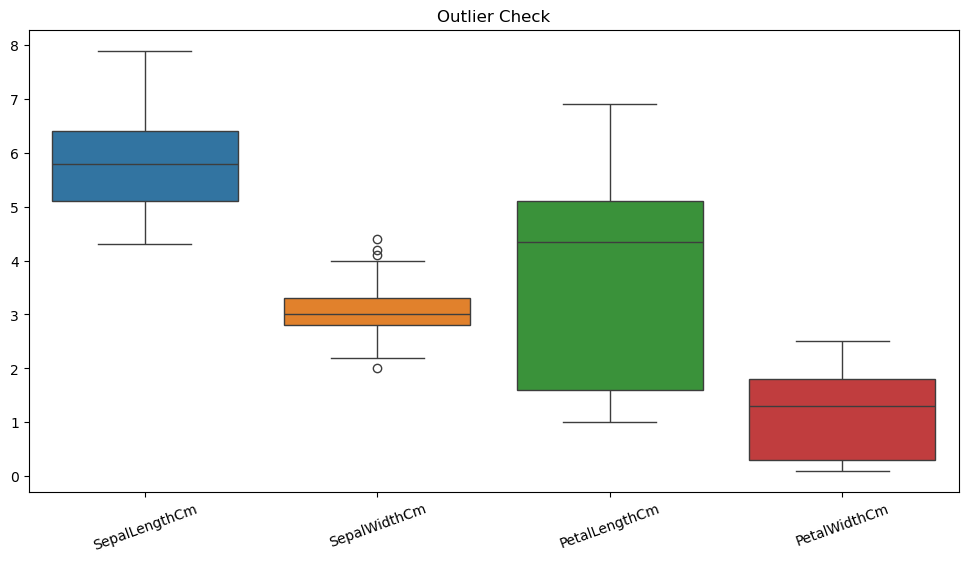

In [13]:
# ============================================================
# 13. OUTLIER CHECK USING BOXPLOT
# ============================================================

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numeric_features])

plt.title("Outlier Check")
plt.xticks(rotation=20)
plt.show()


# 6. Features and Target separate

Machine learning :

### X = input features

```text
SepalLengthCm
SepalWidthCm
PetalLengthCm
PetalWidthCm
```

### y = target

```text
Species
```

Model's doing:

**X → Random Forest → predicted Species**


In [14]:
# ============================================================
# 14. SEPARATE FEATURES (X) AND TARGET (y)
# ============================================================

X = df[numeric_features].copy()
y = df["Species"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
display(X.head())

print("\nTarget:")
display(y.head())


X shape: (150, 4)
y shape: (150,)

Features:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target:


0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object

# 7. Train-Test Split — 80:20

# 7. Train-Test Split — 80:20

Now, we will divide the dataset into two parts:

### Training data — 80%

The model will learn patterns from this data.

### Testing data — 20%

This data will not be shown to the model during the training phase.

We will use this to evaluate how the model performs on **unseen data**.

The purpose of `random_state=42` is to ensure reproducibility.

`stratify=y` ensures that the proportions of the three species remain approximately balanced in both the training and testing sets.


In [15]:
# ============================================================
# 15. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Total samples :", len(X))
print("Training data :", len(X_train))
print("Testing data  :", len(X_test))

print("\nTraining percentage:", len(X_train) / len(X) * 100)
print("Testing percentage :", len(X_test) / len(X) * 100)


Total samples : 150
Training data : 120
Testing data  : 30

Training percentage: 80.0
Testing percentage : 20.0


# 8. Missing-value preprocessing

The Iris dataset is typically clean, but missing values ​​are common in real-world datasets.

Best practice:

**Fit the imputer on the training data.**

Then, use the learned median values ​​to transform both the training and test data.

This ensures that information from the test data does not leak into the training process.

Here, we are using `SimpleImputer(strategy="median")`.


In [16]:
# ============================================================
# 16. HANDLE MISSING VALUES CORRECTLY
# ============================================================

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing values after preprocessing:")
print("Training:", X_train.isnull().sum().sum())
print("Testing :", X_test.isnull().sum().sum())


Missing values after preprocessing:
Training: 0
Testing : 0


# 9. Target Encoding


It is convenient to provide target labels to a Random Forest in numeric form.
Example:

```text
Iris-setosa      → 0
Iris-versicolor  → 1
Iris-virginica   → 2
```

These are just class labels. A value of `2` does not mean that the value for *virginica* is mathematically double that of *versicolor*.


In [17]:
# ============================================================
# 17. ENCODE TARGET LABELS
# ============================================================

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Class mapping:")

for class_name, class_number in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{class_name} -> {class_number}")


Class mapping:
Iris-setosa -> 0
Iris-versicolor -> 1
Iris-virginica -> 2


# 🌳 10. What is Random Forest?

Random Forest is a **supervised machine learning classification algorithm**.

In simple terms:

> Random Forest creates many Decision Trees and combines the decisions from these trees to provide a final prediction.

### A Decision Tree

Suppose a tree asks questions:

```text
Petal Length < 2.5 ?
       /       \
     Yes       No
     ↓          ↓
  Setosa    Petal Width < 1.8 ?
                 /       \
               Yes       No
               ↓          ↓
          Versicolor  Virginica
```

A single tree can make an incorrect prediction.

### Random Forest

suppose 100 trees are there:

```text
Tree 1  → Setosa
Tree 2  → Setosa
Tree 3  → Versicolor
Tree 4  → Setosa
Tree 5  → Setosa
...
Tree 100 → Setosa

Final majority vote → Setosa
```

This process is called **majority voting**.

### Key concepts of Random Forest

**1. Multiple trees**

Using many trees instead of just one.

**2. Random samples**

Trees are trained on different random samples of the training data.

**3. Random features**

Feature subsets are randomized during the splitting process.

**4. Voting**

In classification, the trees cast votes.

**5. Final prediction**

The class that receives the most votes becomes the final predicted class.

### Why Random Forest?

- Powerful for classification tasks
- Capable of handling non-linear relationships
- Generally does not require data scaling
- Provides insights into feature importance
- Typically more robust compared to a single Decision Tree


# 11. Random Forest Parameters

We will use a simple configuration for this lesson.

n_estimators=100

100 decision trees in the forest.

Having more trees can generally make predictions more stable, though it also increases computational cost.

max_depth=5

A maximum depth of 5 for each tree.

This helps prevent the trees from becoming unnecessarily complex.

random_state=42

Ensures reproducible results when the same code is run again.

class_weight="balanced"

If the classes are imbalanced, this helps the model assign appropriate weights to the minority classes. In the Iris dataset, the classes are balanced, so this is not strictly necessary; however, for teaching purposes, we can include this parameter as an optional example.


In [36]:
# ============================================================
# 18. CREATE RANDOM FOREST MODEL
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

print(rf_model)


RandomForestClassifier(max_depth=5, random_state=42)


# 12. Model Training
Random Forest training.

```text
X_train → features
y_train → correct species

        ↓

   Random Forest

        ↓

learned model
```

`fit()` train and learn model with training data.


In [37]:
# ============================================================
# 19. TRAIN RANDOM FOREST
# ============================================================

rf_model.fit(X_train, y_train_encoded)

print("Random Forest training completed successfully!")


Random Forest training completed successfully!


# 13. Prediction

After Training put test data to model for predictions.

Important:

**X_test is unseen for model and not used during tarining.**

Therefore:

`X_test → trained Random Forest → predictions`

then compare predictions to actual `y_test`.


In [38]:
# ============================================================
# 20. PREDICT TEST DATA
# ============================================================

y_pred = rf_model.predict(X_test)

print("Predictions:")
print(y_pred)

print("\nActual labels:")
print(y_test_encoded)


Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 2 2 2 1 0 2 0]

Actual labels:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


# 14. Accuracy

Accuracy indicates:

> Out of the total predictions, how many were correct?

Formula:

**Accuracy = Correct Predictions / Total Predictions**

Example:

If 27 out of 30 test samples are correct:

Accuracy = 27 / 30 = 90%

However, relying solely on accuracy is not always sufficient for evaluating classification models. Therefore, we also consider precision, recall, F1-score, and the confusion matrix.


In [39]:
# ============================================================
# 21. BASIC ACCURACY
# ============================================================

accuracy = accuracy_score(y_test_encoded, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")


Accuracy: 0.9333
Accuracy: 93.33%


# 15. Precision, Recall aur F1-score

### Precision

Out of the instances the model predicted as belonging to a certain class, how many were actually correct?

### Recall

Out of the actual samples belonging to a specific class, how many did the model correctly identify?

### F1-score

A balance between precision and recall.

We will examine these metrics in a class-wise classification report.

In [22]:
# ============================================================
# 22. COMPLETE CLASSIFICATION METRICS
# ============================================================

precision = precision_score(
    y_test_encoded,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test_encoded,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test_encoded,
    y_pred,
    average="weighted",
    zero_division=0
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test_encoded,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


Accuracy : 0.9333
Precision: 0.9333
Recall   : 0.9333
F1-score : 0.9333

Detailed Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



# 16. Confusion Matrix

A confusion matrix shows:

- how many actual Setosa instances were predicted as Setosa
- how many actual Versicolor instances were predicted as Versicolor
- how many actual Virginica instances were predicted as Virginica
- and which samples were assigned to the wrong class

The diagonal values ​​generally represent correct predictions.


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


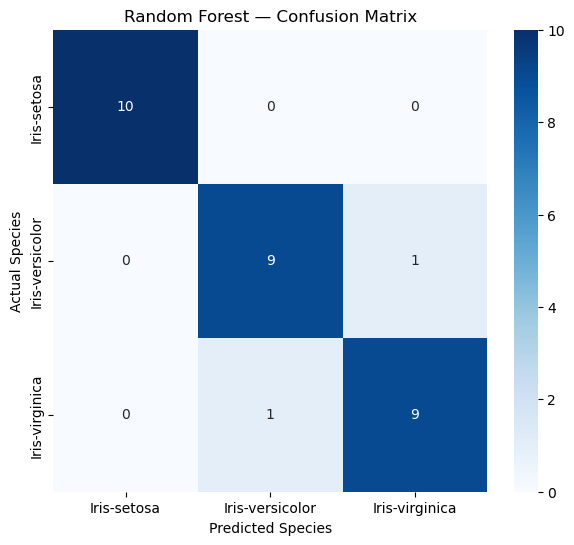

In [23]:
# ============================================================
# 23. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test_encoded, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Random Forest — Confusion Matrix")
plt.show()


# 17. Feature Importance

Random Forest can estimate the contribution of different features toward a prediction.

Possible features:

```text
SepalLengthCm
SepalWidthCm
PetalLengthCm
PetalWidthCm
```

If the importance of 'PetalLength' is high, it means the trained forest found this feature relatively more useful for making splits.

**Important:** Feature importance does not prove causation


,Feature,Importance
3,PetalWidthCm,0.438141
2,PetalLengthCm,0.431641
0,SepalLengthCm,0.115972
1,SepalWidthCm,0.014246


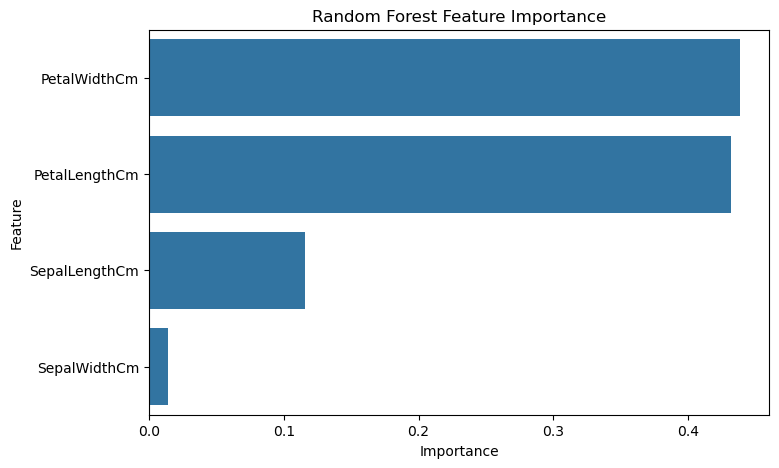

In [24]:
# ============================================================
# 24. FEATURE IMPORTANCE
# ============================================================

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


# 18. Random Forest individual trees visualization

A Random Forest consists of multiple decision trees.

By visualizing the first tree, we can show students what an actual decision tree within the forest looks like.

**Note:** The entire forest would be a massive diagram; therefore, it is better to visualize just one tree for teaching purposes


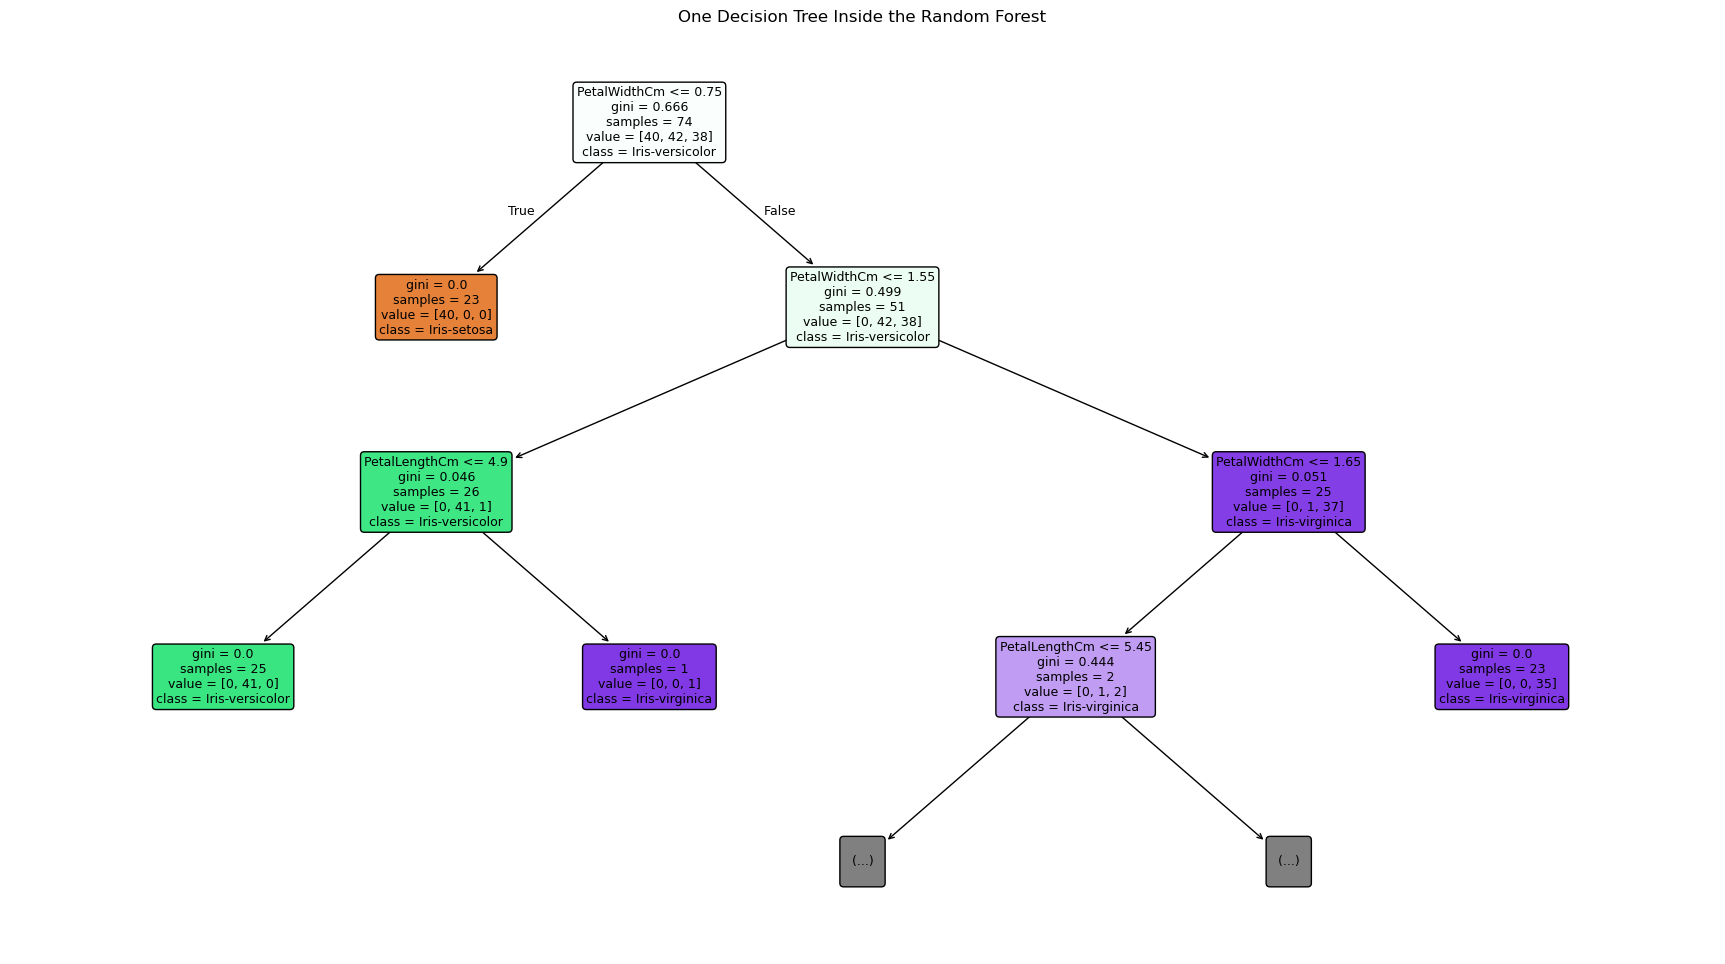

In [25]:
# ============================================================
# 25. VISUALIZE ONE DECISION TREE FROM THE FOREST
# ============================================================

from sklearn.tree import plot_tree

plt.figure(figsize=(22, 12))

plot_tree(
    rf_model.estimators_[0],
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("One Decision Tree Inside the Random Forest")
plt.show()


# 19. New Flower Prediction

give **new flower** to model that species is not shown to the model.

Example:

- Sepal Length = 5.1 cm
- Sepal Width = 3.5 cm
- Petal Length = 1.4 cm
- Petal Width = 0.2 cm

Model predict:

**Which Iris species?**


In [26]:
# ============================================================
# 26. PREDICT A NEW FLOWER
# ============================================================

new_flower = pd.DataFrame({
    "SepalLengthCm": [5.1],
    "SepalWidthCm": [3.5],
    "PetalLengthCm": [1.4],
    "PetalWidthCm": [0.2]
})

# Apply the same preprocessing learned from training data.
new_flower_processed = pd.DataFrame(
    imputer.transform(new_flower),
    columns=new_flower.columns
)

prediction_encoded = rf_model.predict(new_flower_processed)[0]

prediction_species = label_encoder.inverse_transform(
    [prediction_encoded]
)[0]

print("New flower measurements:")
display(new_flower)

print("Predicted species:", prediction_species)


New flower measurements:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2


Predicted species: Iris-setosa


# 20. Prediction Probability

Random Forest can also provide an estimated probability distribution for each class via `predict_proba()`.

Example:

```text
Setosa      → 98%
Versicolor  → 1%
Virginica   → 1%
```

The highest probability class becomes the predicted class.


In [27]:
# ============================================================
# 27. PREDICTION PROBABILITIES
# ============================================================

probabilities = rf_model.predict_proba(new_flower_processed)[0]

probability_df = pd.DataFrame({
    "Species": label_encoder.classes_,
    "Probability": probabilities
})

probability_df["Probability (%)"] = (
    probability_df["Probability"] * 100
)

display(probability_df)


,Species,Probability,Probability (%)
0,Iris-setosa,1.0,100.0
1,Iris-versicolor,0.0,0.0
2,Iris-virginica,0.0,0.0


# 21. Final Model Summary

We performed the complete machine-learning pipeline:

### Step 1
Kaggle Iris dataset loaded from Google Drive.

### Step 2
Inspected the dataset.

### Step 3
Missing values ​​and duplicates are checked.

### Step 4
Unnecessary `Id` column removed.

### Step 5
Of EDA and visualization.

### Step 6
Features `X` and target `y` are separated.

### Step 7
The dataset was divided into **80:20** train-test split.

### Step 8
Target labels encoded.

### Step 9
Created Random Forest model.

### Step 10
Trained 100 decision trees.

### Step 11
Made predictions on test data.

### Step 12
Accuracy, precision, recall and F1-score calculated.

### Step 13
Create confusion matrix.

### Step 14
Feature importance calculated.

### Step 15
New flower species predicted.

# 🔑 One-line concept to remember

**Data → Preprocessing → Train/Test Split → Random Forest learns from training data → Prediction on unseen test data → Evaluation**

And:

**Random Forest = Many Decision Trees + Randomness + Voting**
